# Packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

# Load Data

In [2]:
df = pd.read_csv('../data/swat-2015-data.csv')

In [3]:
print(df.shape)
df.head()

(449919, 53)


,Timestamp,FIT101,LIT101,MV101,P101,P102,AIT201,AIT202,AIT203,FIT201,...,P501,P502,PIT501,PIT502,PIT503,FIT601,P601,P602,P603,Normal/Attack
0,28/12/2015 10:00:00 AM,2.427057,522.8467,2,2,1,262.0161,8.396437,328.6337,2.445391,...,2,1,250.8652,1.649953,189.5988,0.000128,1,1,1,Normal
1,28/12/2015 10:00:01 AM,2.446274,522.8860,2,2,1,262.0161,8.396437,328.6337,2.445391,...,2,1,250.8652,1.649953,189.6789,0.000128,1,1,1,Normal
2,28/12/2015 10:00:02 AM,2.489191,522.8467,2,2,1,262.0161,8.394514,328.6337,2.442316,...,2,1,250.8812,1.649953,189.6789,0.000128,1,1,1,Normal
3,28/12/2015 10:00:03 AM,2.534350,522.9645,2,2,1,262.0161,8.394514,328.6337,2.442316,...,2,1,250.8812,1.649953,189.6148,0.000128,1,1,1,Normal
4,28/12/2015 10:00:04 AM,2.569260,523.4748,2,2,1,262.0161,8.394514,328.6337,2.443085,...,2,1,250.8812,1.649953,189.5027,0.000128,1,1,1,Normal


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 449919 entries, 0 to 449918
Data columns (total 53 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0    Timestamp     449919 non-null  str    
 1   FIT101         449919 non-null  float64
 2   LIT101         449919 non-null  float64
 3    MV101         449919 non-null  int64  
 4   P101           449919 non-null  int64  
 5   P102           449919 non-null  int64  
 6    AIT201        449919 non-null  float64
 7   AIT202         449919 non-null  float64
 8   AIT203         449919 non-null  float64
 9   FIT201         449919 non-null  float64
 10   MV201         449919 non-null  int64  
 11   P201          449919 non-null  int64  
 12   P202          449919 non-null  int64  
 13  P203           449919 non-null  int64  
 14   P204          449919 non-null  int64  
 15  P205           449919 non-null  int64  
 16  P206           449919 non-null  int64  
 17  DPIT301        449919 non-null  float64


# Visulization

Since the whole dataset time line is too long, here we only visulize 29 Dec 2015's data, you can easily change to what date you want to visulize by modifing start and end indexes. 

In [5]:
# Dataset Start Time and End Time
df_time_start = np.array('2015-12-28T10:00:00', dtype=np.datetime64)
df_time_end = np.array('2016-01-02T14:59:59', dtype=np.datetime64)  # 2:59:59 PM, not AM

# Visulization Strat Time and End Time
time_start = np.array('2015-12-29T00:00:00', dtype=np.datetime64)
time_end = np.array('2015-12-30T00:00:00', dtype=np.datetime64)
time_len = int((time_end - time_start) / np.timedelta64(1, 's'))

## Set Anomaly Time Regions

The original version of this tool hand-transcribed attack windows from iTrust's `List_of_attacks_Final.pdf` for one specific day. That's fragile and can drift from whatever data file is actually loaded above.

Instead, this derives attack windows directly from the `Normal/Attack` column already present in the real dataset loaded in cell 4 — the ground-truth label iTrust ships with every row. No external file, no manual transcription.

One limitation: the per-row label only says whether an attack was active, not *which* sensor was the intended target (that finer detail lives only in iTrust's separate `List_of_attacks_Final` document, which isn't part of this dataset). So the plot below shades every sensor during a real attack window, rather than picking out one "attacked" sensor per window.

In [6]:
# Real, data-derived attack mask -- straight from the dataset's own label
# column, case/space-insensitive so iTrust's "A ttack" typo still counts.
label = df['Normal/Attack'].astype(str).str.strip().str.lower().str.replace(' ', '', regex=False)
is_attack = (label != 'normal').to_numpy()


def contiguous_runs(mask):
    """[start, end) index pairs for each contiguous run of True."""
    mask = np.asarray(mask).astype(bool)
    padded = np.concatenate(([0], mask.astype(int), [0]))
    diff = np.diff(padded)
    starts = np.flatnonzero(diff == 1)
    ends = np.flatnonzero(diff == -1)
    return list(zip(starts.tolist(), ends.tolist()))


idx_start = int((time_start - df_time_start) / np.timedelta64(1, 's'))
idx_end = int((time_end - df_time_start) / np.timedelta64(1, 's'))
x = time_start + np.arange(0, time_len, 1)

# Positions are relative to idx_start, i.e. directly usable as indices into `x`.
attack_windows = contiguous_runs(is_attack[idx_start:idx_end])
print(f"{len(attack_windows)} real attack window(s) in this period (from the data itself):")
for s, e in attack_windows:
    print(f"  {x[s]}  ->  {x[e - 1]}  ({e - s}s)")

9 real attack window(s) in this period (from the data itself):
  2015-12-29T06:30:00  ->  2015-12-29T06:42:00  (721s)
  2015-12-29T11:11:25  ->  2015-12-29T11:15:17  (233s)
  2015-12-29T11:35:40  ->  2015-12-29T11:42:50  (431s)
  2015-12-29T11:57:25  ->  2015-12-29T12:02:00  (276s)
  2015-12-29T14:38:12  ->  2015-12-29T14:50:08  (717s)
  2015-12-29T18:10:43  ->  2015-12-29T18:15:01  (259s)
  2015-12-29T18:15:43  ->  2015-12-29T18:22:17  (395s)
  2015-12-29T18:30:00  ->  2015-12-29T18:42:00  (721s)
  2015-12-29T22:55:18  ->  2015-12-29T23:03:00  (463s)


## Plot

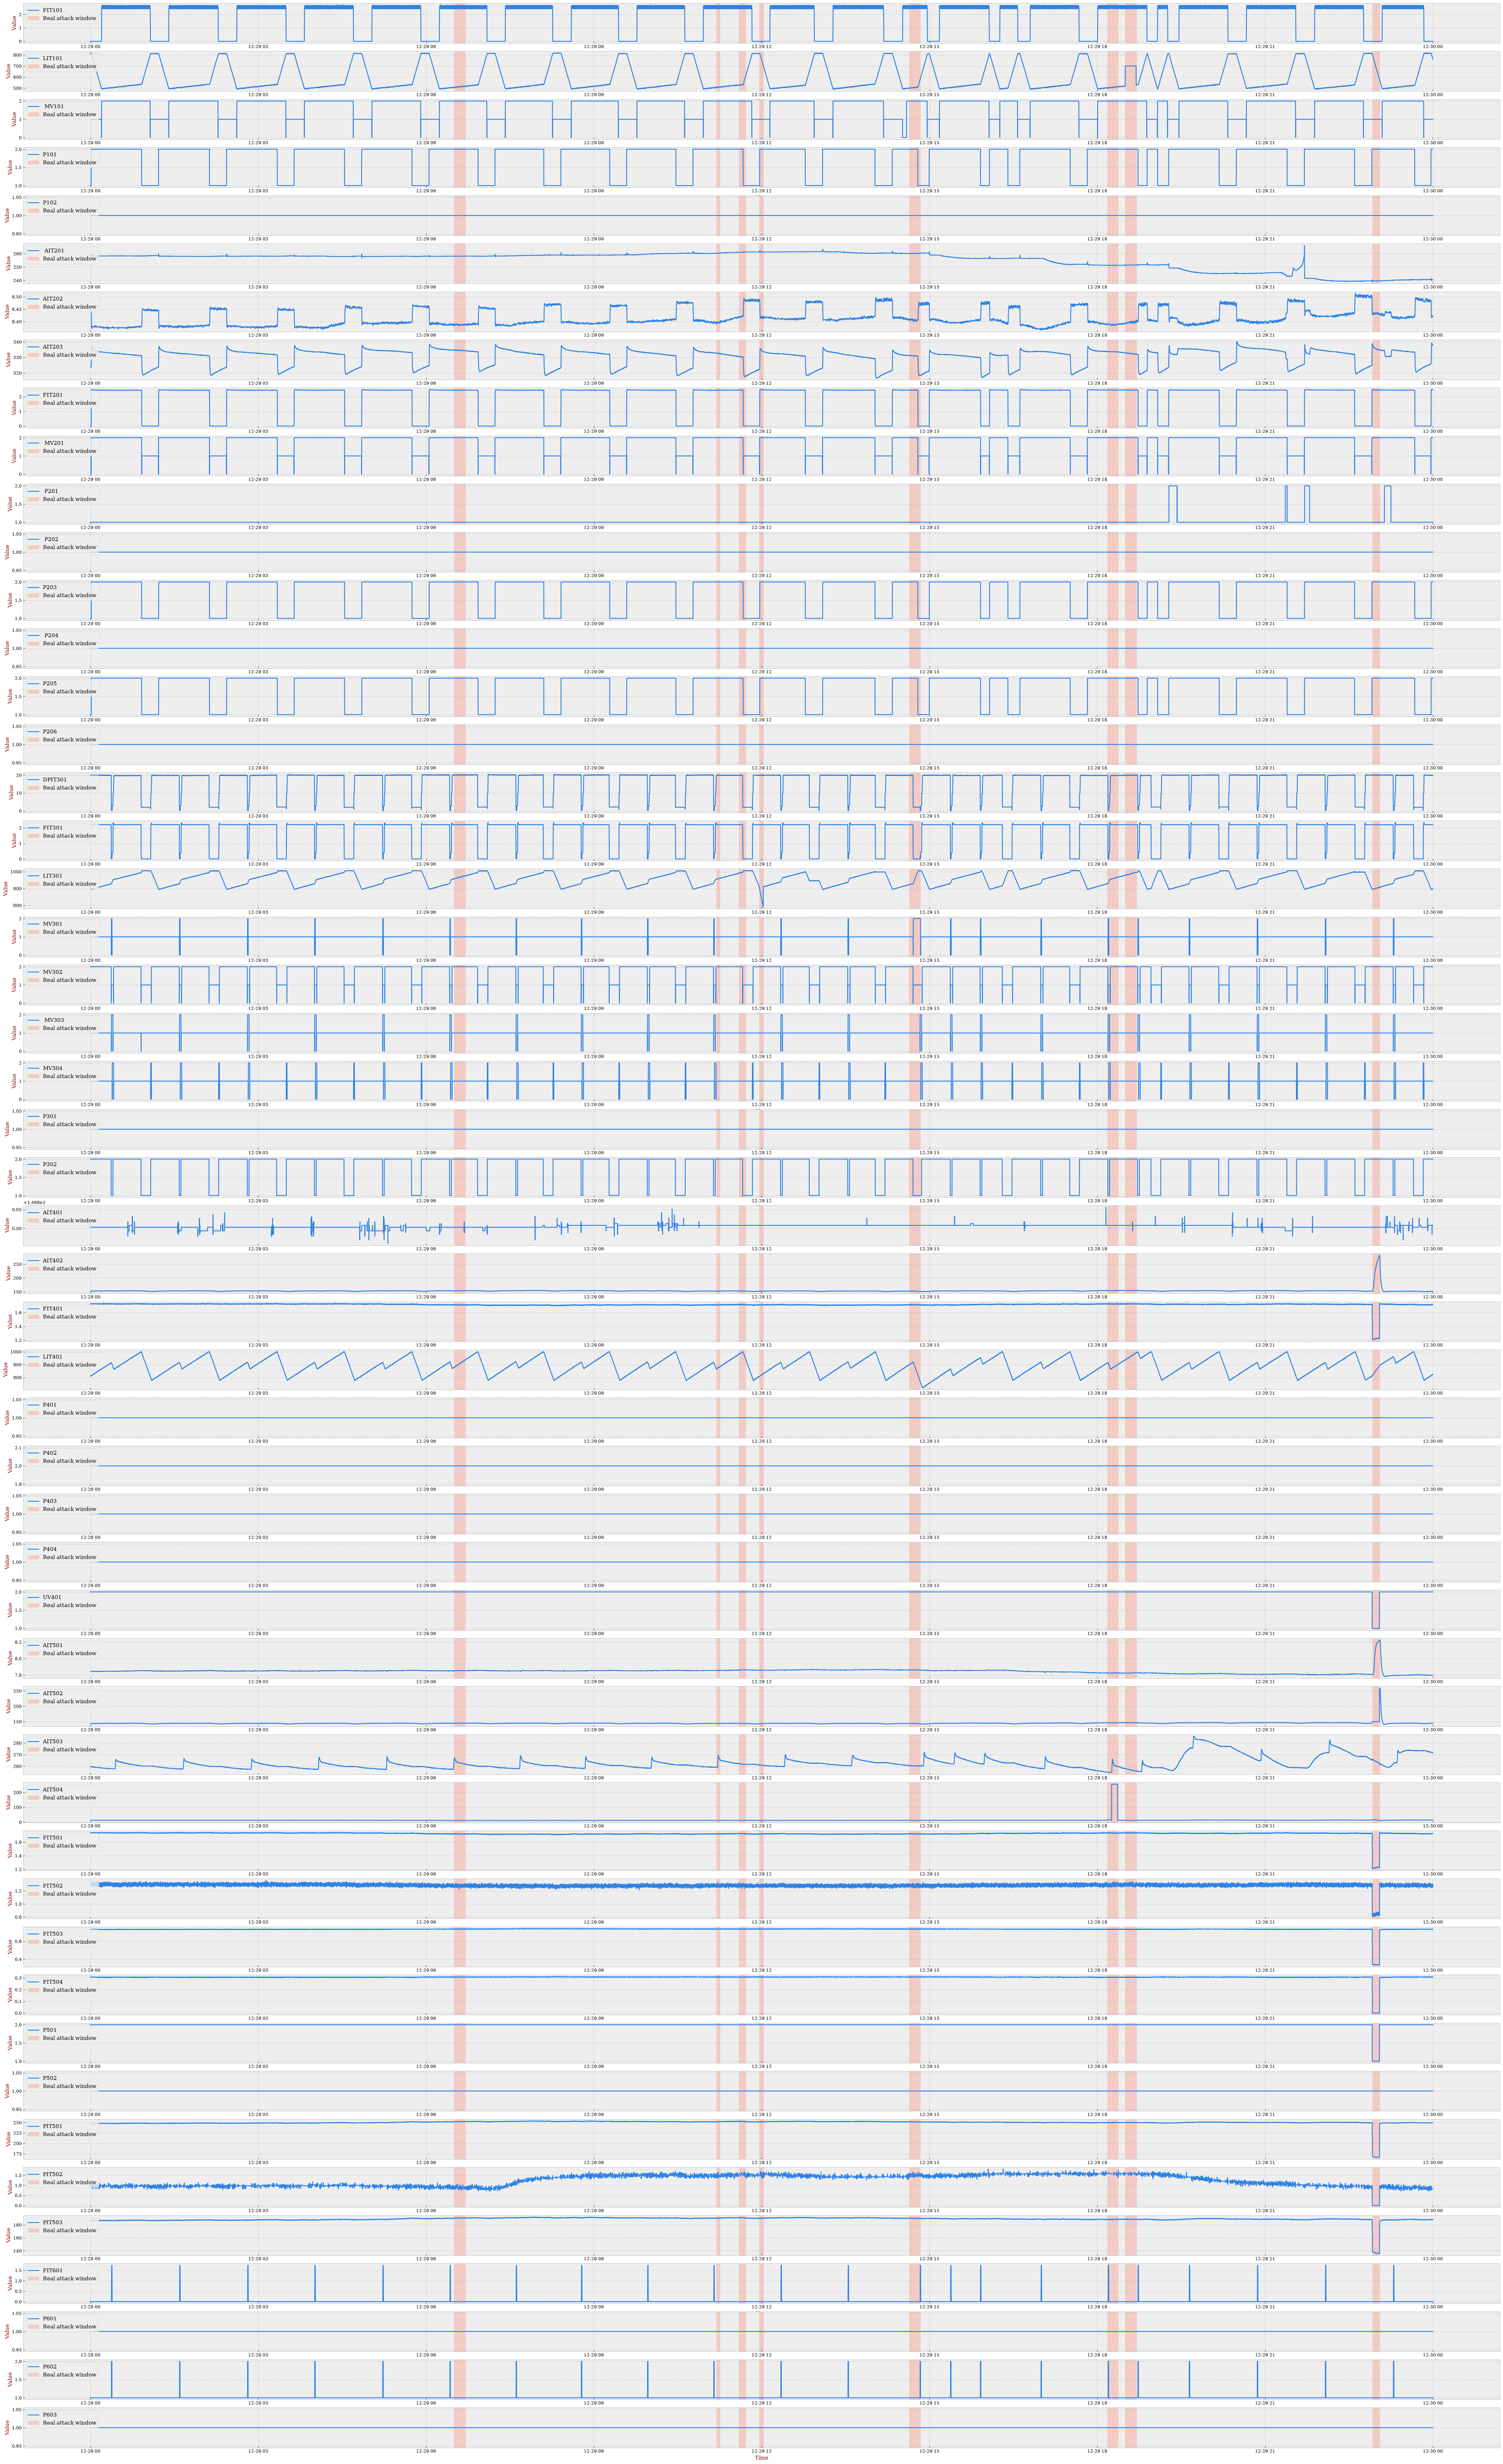

In [7]:
with plt.style.context('bmh'):
    font = {'color': 'darkred', 'size': 12, 'family': 'serif'}
    font_legend = {'size': 12, 'family': 'serif'}

    fig, axs = plt.subplots(51, 1, figsize=(60, 100))

    for i in range(51):
        axs[i].plot(x, df.iloc[idx_start:idx_end, i+1], label=df.columns[i+1], color='#2f83e4')
        axs[i].set_xlabel('Time', fontdict=font)
        axs[i].set_ylabel('Value', fontdict=font)

        for j, (s, e) in enumerate(attack_windows):
            axs[i].axvspan(
                x[s], x[e - 1],
                color='tomato', alpha=0.25,
                label='Real attack window' if j == 0 else None,
            )

        axs[i].legend(loc='upper left', prop=font_legend)
        labels = axs[i].get_xticklabels() + axs[i].get_yticklabels()
        [label.set_fontname('serif') for label in labels]

plt.savefig('../fig/swat-2015.png')
# Explicit show + close: at 51 subplots this figure is ~6000x10000px, big
# enough that the inline backend's implicit auto-display was silently
# dropping it in some kernel sessions. Forcing it here makes the output
# reliable both headless (nbconvert) and live (VS Code).
plt.show()
plt.close(fig)